In [1]:
# IMPORTS -------------------------------------------------------------------- #
import os
import sys
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import pandas as pd
import seaborn as sns

import utils

workspace,experiment=utils.workspace()

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import scanpy as sc

In [2]:
# verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.verbosity = 3
sc.set_figure_params(dpi=80,facecolor='white', frameon=True, dpi_save=150, scanpy=True, fontsize=14, transparent=False, color_map=None)

In [3]:
result_dir = experiment/'results/mad_workflow'
data_file = result_dir/'pbmc3k_mad_norm.h5ad'
result_file = result_dir/'pbmc3k_annotated.h5ad'

In [4]:
adata = sc.read(data_file)
adata

AnnData object with n_obs × n_vars = 2560 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'scrublet'
    layers: 'counts', None (.X)

# Prep

In [5]:
adata.layers["scaled"] = adata.X.toarray()
sc.pp.regress_out(adata, ["total_counts", "pct_counts_mt"], layer="scaled")
sc.pp.scale(adata, max_value=10, layer="scaled")


regressing out ['total_counts', 'pct_counts_mt']
    finished (0:00:01)


# PCA

In [6]:
sc.tl.pca(adata, layer='scaled', n_comps=50, zero_center=True, mask_var="highly_variable", svd_solver='arpack')

computing PCA
    with n_comps=50
    finished (0:00:33)


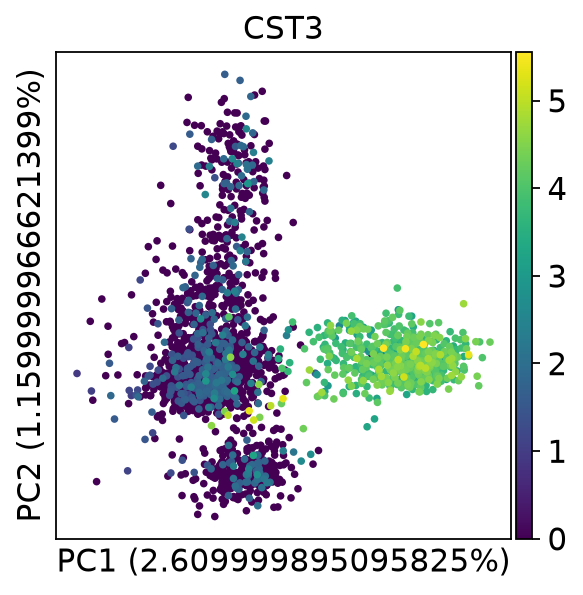

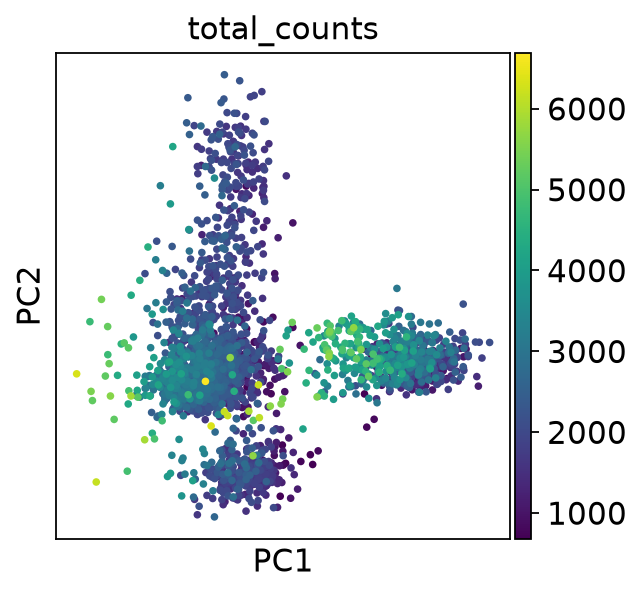

In [7]:
sc.pl.pca(adata, annotate_var_explained=True, color="CST3")
sc.pl.pca(adata, color="total_counts")

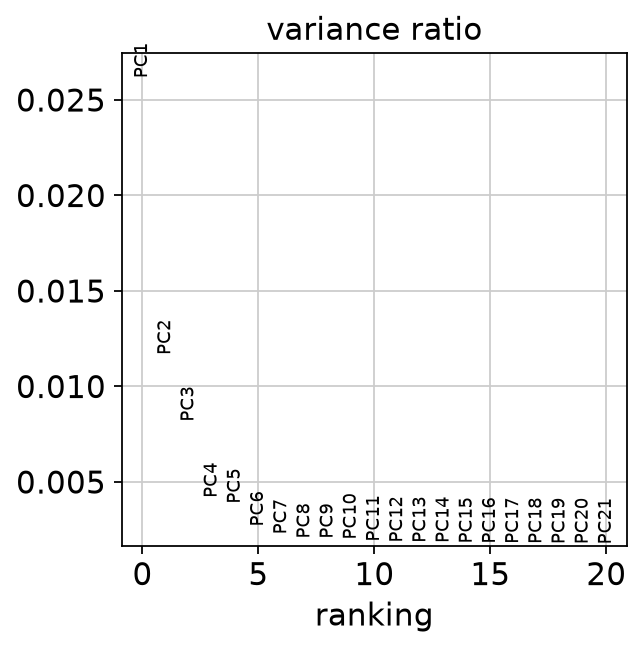

In [8]:
sc.pl.pca_variance_ratio(adata, n_pcs=20)
pca_n = 10

# Neighborhood graph

In [9]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=pca_n, use_rep='X_pca')

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:48)


In [10]:
RES=0.3
sc.tl.leiden(adata, flavor='igraph',resolution=RES,random_state=0,n_iterations=2,directed=False)

running Leiden clustering
    finished: found 7 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


In [11]:
sc.tl.paga(adata)
sc.pl.paga(adata, plot=False)


running PAGA
    finished: added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns) (0:00:00)
--> added 'pos', the PAGA positions (adata.uns['paga'])


computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:03)


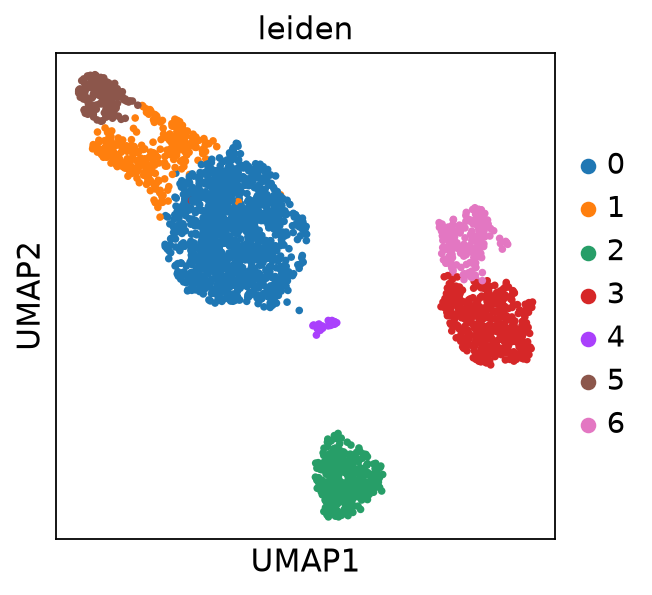

In [12]:
sc.tl.umap(adata)
sc.pl.umap(adata, color="leiden")

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:09)


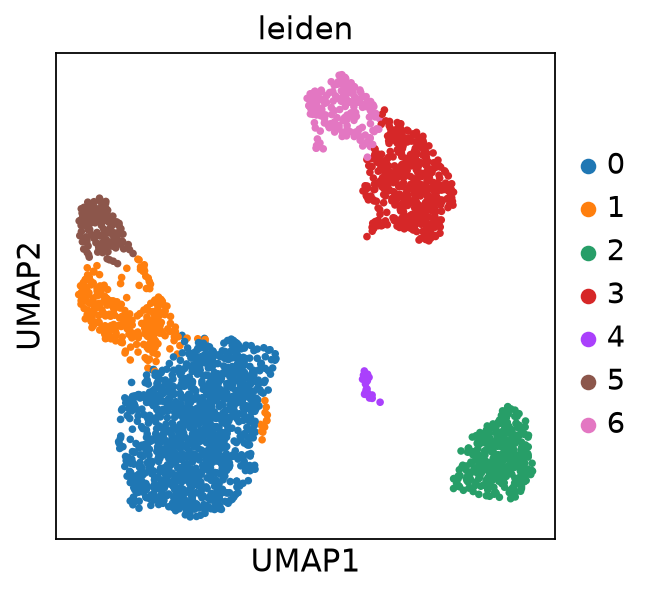

In [13]:

sc.tl.umap(adata, init_pos='paga')
fig = sc.pl.umap(adata, color="leiden", show=False)
plt.savefig(experiment/f'figures/clustering/MAD/leiden_{pca_n}PCA_{RES}res_umap.png')


# Marker Genes

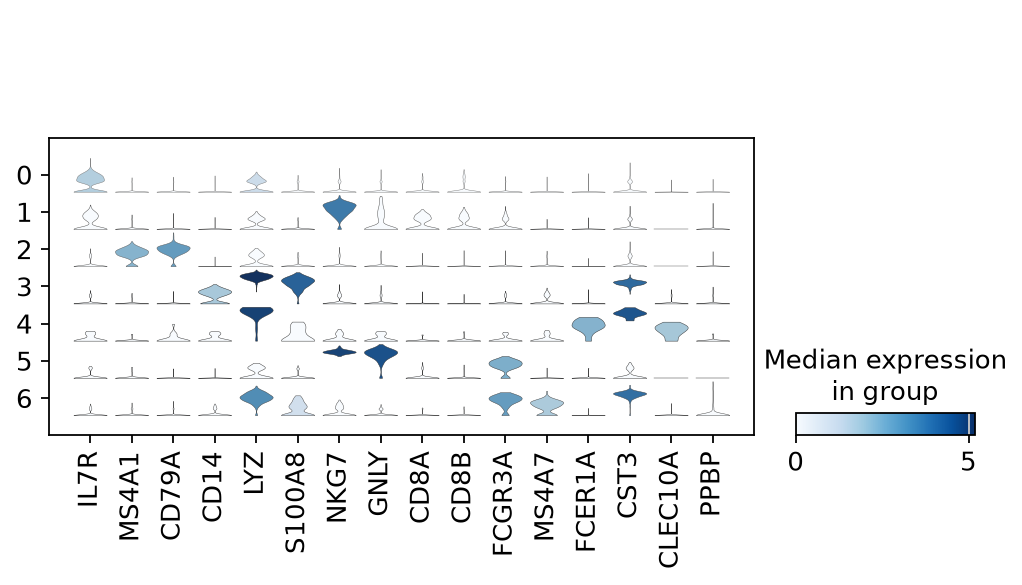

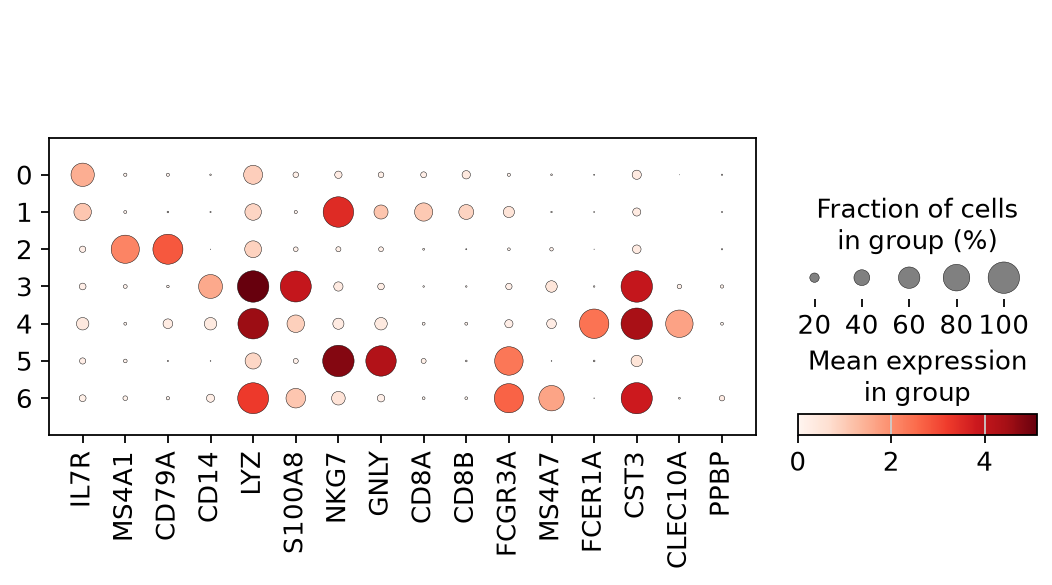

In [14]:
# SOME MARKER GENES ---------------------------------------------------------- #
# IL7R - CD4 T cells
# MS4A1 - B cells
# CD14, LYZ - CD14+ Monocytes
# CD8A - CD8 T cells
# GNLY, NKG7 - NK cells
# FCGR3A, MS4A7 - FCGR3A+ Monocytes
# FCER1A, CST3 - Dendritic Cells
# PPBP - Megakaryocytes
# ---------------------------------------------------------------------------- #
marker_genes = [
    *["IL7R", "CD79A", "MS4A1", "CD8A", "CD8B", "LYZ", "CD14"],
    *["LGALS3", "S100A8", "GNLY", "NKG7", "KLRB1"],
    *["FCGR3A", "MS4A7", "FCER1A", "CST3", "PPBP"],
]

marker_genes = {
    "CD4 T" : ['IL7R'],
    "B" : ['MS4A1','CD79A'],
    "CD14+ Monocytes" : ['CD14','LYZ','S100A8'],
    "NK" : ['NKG7','GNLY'],
    "CD8 T" : ['CD8A','CD8B'],
    "FCGR3A+ Monocytes" : ['FCGR3A','MS4A7'],
    "Dendritic" : ['FCER1A','CST3','CLEC10A'],
    "Megakaryocytes" : ['PPBP'],
    # "More" : ['LGALS3','KLRB1']
}

sc.set_figure_params(scanpy=True)
sc.pl.stacked_violin(adata, [g for v in marker_genes.values() for g in v], groupby="leiden",dodge=False)
sc.pl.dotplot(adata, [g for v in marker_genes.values() for g in v], groupby="leiden")


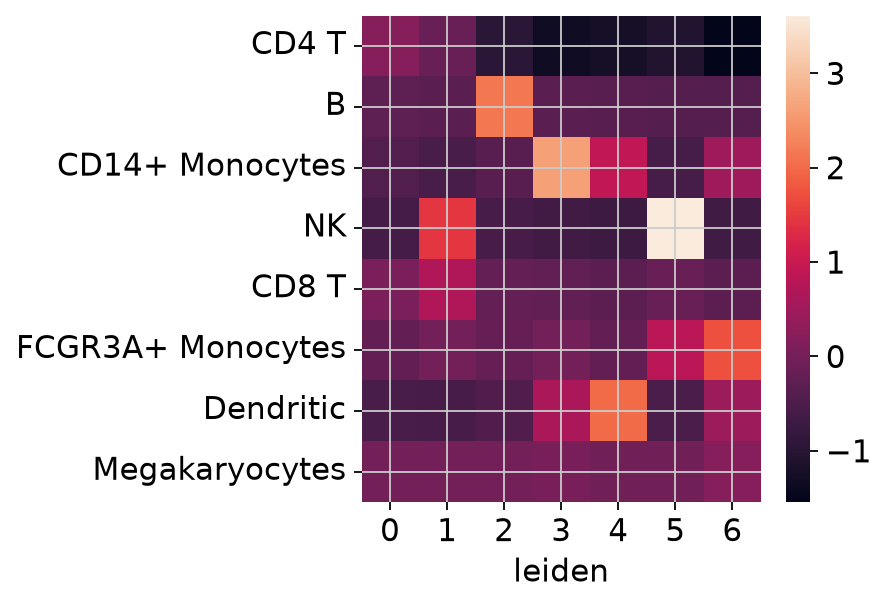

In [15]:
sc.settings.verbosity = 1
adata_an = adata.copy()
for celltype,genes in marker_genes.items():
    sc.tl.score_genes(adata_an, gene_list=genes, score_name=celltype,)

markers = adata_an.obs.groupby('leiden')[list(marker_genes.keys())].mean()
sns.heatmap(markers.T)
plt.show()


In [16]:
# CELLTYPES BASED ON SC.TL.SCORE_GENES --------------------------------------- #
sc.settings.verbosity = 1

def find_optimum(gene_scores,group,idx=0):
    prediction = gene_scores.loc[group].sort_values(ascending=False).index[idx]
    confirm =  markers[prediction].sort_values(ascending=False).index[0]
    if confirm == group:
        return prediction
    elif idx+1 == gene_scores.shape[0]:
        return "None"
    else:
        return find_optimum(gene_scores,group,idx=idx+1)

new_names = {gr: find_optimum(markers,gr) for gr in adata_an.obs.leiden.cat.categories}
print('\n'.join([f'{k} : {v}' for k,v in new_names.items()]))

0 : CD4 T
1 : CD8 T
2 : B
3 : CD14+ Monocytes
4 : Dendritic
5 : NK
6 : FCGR3A+ Monocytes


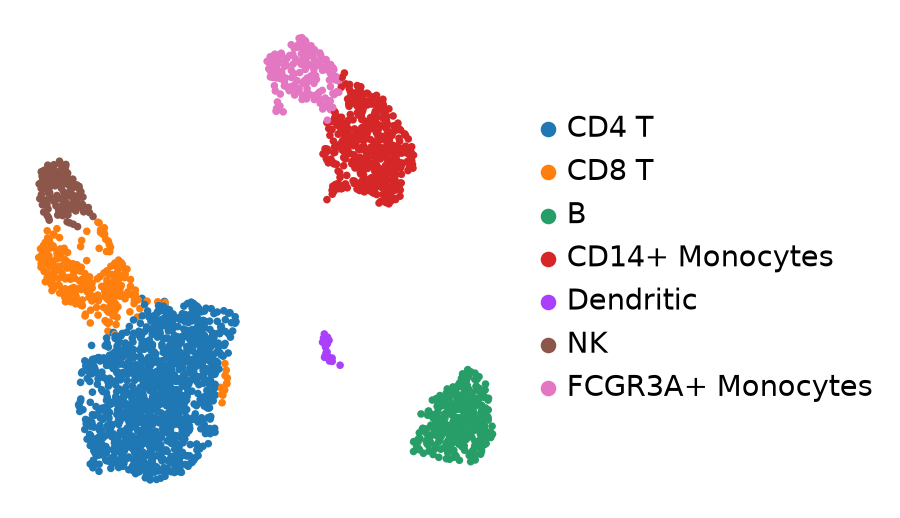

In [17]:
# RENAME LEIDEN CLUSTERS ----------------------------------------------------- #
adata.obs['celltype'] = adata.obs['leiden']
adata.rename_categories('celltype',list(new_names.values()))
sc.pl.umap(adata, color="celltype", title="", frameon=False)

# Save data

In [18]:
adata.write(result_file)